# **Q1. Daily Closing Index for CSI 300 Index**

(a) Deriving Returns and Summary Statistics (Mean, Standard Deviation, Skewness, Kurtosis)

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import skew, kurtosis

df = pd.read_excel("IDX_Idxtrd.xlsx", skiprows=2)
print(df.head())

   No Unit   No Unit .1  No Unit .2
0       300  2010-01-04     3535.23
1       300  2010-01-05     3564.04
2       300  2010-01-06     3541.73
3       300  2010-01-07     3471.46
4       300  2010-01-08     3480.13


/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [62]:
files = [
    "IDX_Idxtrd.xlsx",
    "IDX_Idxtrd2.xlsx",
    "IDX_Idxtrd3.xlsx",
    "IDX_Idxtrd4.xlsx"
]

df_list = []

for f in files:
    df = pd.read_excel(f, skiprows=2, header=None)
    df.columns = ['Indexcd', 'date', 'close']
    df_list.append(df)

csi = pd.concat(df_list, ignore_index=True)
csi['date'] = pd.to_datetime(csi['date'], errors='coerce')
csi['close'] = pd.to_numeric(csi['close'], errors='coerce')
csi = csi.dropna()
csi = csi.sort_values('date')

print(csi.head())
print(csi.shape)

/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


  Indexcd       date    close
1  000300 2010-01-04  3535.23
2  000300 2010-01-05  3564.04
3  000300 2010-01-06  3541.73
4  000300 2010-01-07  3471.46
5  000300 2010-01-08  3480.13
(3886, 3)


/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/tmp/ipykernel_8144/3632771666.py:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  csi['date'] = pd.to_datetime(csi['date'], errors='coerce')


In [63]:
csi.set_index('date', inplace=True)
monthly_price = csi['close'].resample('M').last()
monthly_returns = monthly_price.pct_change().dropna()
print("Mean:", monthly_returns.mean())
print("Std:", monthly_returns.std())
print("Skewness:", skew(monthly_returns))
print("Kurtosis:", kurtosis(monthly_returns))

Mean: 0.003849876672165607
Std: 0.06270899431814454
Skewness: 0.5464156773773022
Kurtosis: 2.1201301487823754


/tmp/ipykernel_8144/1405611535.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_price = csi['close'].resample('M').last()


(b) Plotting Histogram for CSI 300 Monthly Returns

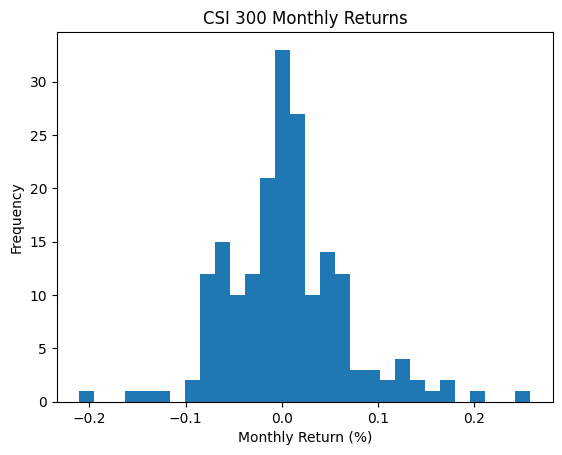

In [64]:
plt.hist(monthly_returns, bins=30)
plt.title("CSI 300 Monthly Returns")
plt.xlabel("Monthly Return (%)")
plt.ylabel("Frequency")
plt.show()

(c) Does CSI 300 Index follow normal distribution? (please see discussion on results pdf file)

# **Q2. Applying Jensen, Black, and Scholes Method**

(a) Download Weekly Returns Without Cash Dividend Reinvested for all A-share Mainboard stocks from CSMAR (please see included Excel files TRD_Week.xlsx and TRD_Week1.xlsx)

In [65]:
files2 = [
    "TRD_Week.xlsx",
    "TRD_Week1.xlsx"
]

df_list2 = []

for f in files2:
    df2 = pd.read_excel(f, skiprows=2, header=None)
    df2.columns = ['Stkcd', 'TrdWeek', 'Return']
    df_list2.append(df2)

weekly = pd.concat(df_list2, ignore_index=True)
weekly['TrdWeek'] = pd.to_datetime(weekly['TrdWeek'], errors='coerce')
weekly['Return'] = pd.to_numeric(weekly['Return'], errors='coerce')
weekly = weekly.dropna()
weekly = weekly.sort_values('TrdWeek')

print(weekly.head())
print(weekly.shape)

#df = pd.read_excel("TRD_Week.xlsx")
#print(df.head())

/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.12/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/tmp/ipykernel_8144/2072145463.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  weekly['TrdWeek'] = pd.to_datetime(weekly['TrdWeek'], errors='coerce')


          Stkcd    TrdWeek    Return
1        000001 2020-01-01  0.044377
455974   300004 2020-01-01 -0.030702
456283   300005 2020-01-01  0.033937
889729   600308 2020-01-01  0.004357
1278032  603916 2020-01-01 -0.027251
(313974, 3)


(b) Calculating Weekly Market Returns

In [66]:
weekly_market_returns = weekly.groupby('TrdWeek')['Return'].mean().reset_index()
weekly_market_returns.rename(columns={'Return': 'MarketReturn'}, inplace=True)
print(weekly_market_returns.head())

     TrdWeek  MarketReturn
0 2020-01-01      0.024076
1 2020-02-01      0.019949
2 2020-03-01     -0.000444
3 2020-04-01     -0.035383
4 2020-06-01     -0.031259


(c) Load Weekly Risk-Free Return

In [67]:
df3 = pd.read_stata('riskfree_w.dta')
#print(df3.head()) #riskfree_w, tw
weekly_rf = df3[['tw','riskfree_w']].dropna()
weekly_rf = weekly_rf.sort_values('tw').reset_index(drop=True)
weekly_rf.columns = ['TrdWeek', 'Rf']

weekly_rf['TrdWeek'] = pd.to_datetime(weekly_rf['TrdWeek'], errors='coerce')
weekly_rf['Rf'] = pd.to_numeric(weekly_rf['Rf'], errors='coerce')
print(weekly_rf.head())

     TrdWeek        Rf
0 2020-01-01  0.000286
1 2020-02-01  0.000286
2 2020-03-01  0.000286
3 2020-04-01  0.000286
4 2020-05-01  0.000286


(d) Replicating Tables 1 - 3

In [68]:
weekly_combined = pd.merge(weekly_market_returns, weekly_rf, on='TrdWeek', how='outer')
weekly_combined = weekly_combined.sort_values('TrdWeek').reset_index(drop=True)
weekly_combined['MarketReturn'] = weekly_combined['MarketReturn'].ffill()
weekly_combined['Rf'] = weekly_combined['Rf'].ffill()

base = weekly_combined.copy()
weekly = weekly.drop(columns=['MarketReturn', 'Rf'], errors='ignore')
weekly_full = weekly.merge(base, on='TrdWeek', how='left')
weekly_full['ExcessReturn'] = weekly_full['Return'] - weekly_full['Rf']
weekly_full['ExcessMarketReturn'] = weekly_full['MarketReturn'] - weekly_full['Rf']

weekly_full = weekly_full.drop(columns=['MarketReturn_x', 'MarketReturn_y', 'Rf_x', 'Rf_y'], errors='ignore')

print(weekly_full.head())

    Stkcd    TrdWeek    Return  MarketReturn        Rf  ExcessReturn  \
0  000001 2020-01-01  0.044377      0.024076  0.000286      0.044091   
1  300004 2020-01-01 -0.030702      0.024076  0.000286     -0.030988   
2  300005 2020-01-01  0.033937      0.024076  0.000286      0.033651   
3  600308 2020-01-01  0.004357      0.024076  0.000286      0.004071   
4  603916 2020-01-01 -0.027251      0.024076  0.000286     -0.027537   

   ExcessMarketReturn  
0             0.02379  
1             0.02379  
2             0.02379  
3             0.02379  
4             0.02379  


In [69]:
#2(d) i. divide the entire sample period into 2 parts of equal number of weeks
weekly_full = weekly_full.sort_values('TrdWeek').reset_index(drop=True)

weeks_unique = weekly_full['TrdWeek'].unique()
half_weeks = len(weeks_unique) // 2

first_half_weeks = weeks_unique[:half_weeks]
second_half_weeks = weeks_unique[half_weeks:]

weekly_first = weekly_full[weekly_full['TrdWeek'].isin(first_half_weeks)].copy()
weekly_second = weekly_full[weekly_full['TrdWeek'].isin(second_half_weeks)].copy()

#forward fill
weekly_first['MarketReturn'] = weekly_first['MarketReturn'].ffill()
weekly_first['ExcessMarketReturn'] = weekly_first['ExcessMarketReturn'].ffill()
weekly_second['MarketReturn'] = weekly_second['MarketReturn'].ffill()
weekly_second['ExcessMarketReturn'] = weekly_second['ExcessMarketReturn'].ffill()

print(weekly_first['TrdWeek'].nunique())
print(weekly_second['TrdWeek'].nunique())

print(weekly_first.head())
print(weekly_second.head())

33
33
    Stkcd    TrdWeek    Return  MarketReturn        Rf  ExcessReturn  \
0  000001 2020-01-01  0.044377      0.024076  0.000286      0.044091   
1  002153 2020-01-01  0.004615      0.024076  0.000286      0.004329   
2  601798 2020-01-01  0.016103      0.024076  0.000286      0.015817   
3  002154 2020-01-01  0.027950      0.024076  0.000286      0.027664   
4  601020 2020-01-01  0.003286      0.024076  0.000286      0.003000   

   ExcessMarketReturn  
0             0.02379  
1             0.02379  
2             0.02379  
3             0.02379  
4             0.02379  
         Stkcd    TrdWeek    Return  MarketReturn        Rf  ExcessReturn  \
139770  603332 2023-02-01 -0.023744      0.000551  0.000315     -0.024059   
139771  600941 2023-02-01  0.027090      0.000551  0.000315      0.026775   
139772  688320 2023-02-01 -0.095018      0.000551  0.000315     -0.095333   
139773  300385 2023-02-01 -0.013333      0.000551  0.000315     -0.013648   
139774  688526 2023-02-01  0.104

In [70]:
#2(d) ii. First-Half OLS Regression Results (10 Stocks)
import statsmodels.api as sm
import pandas as pd

weekly_first['ExcessReturn'] = weekly_first['Return'] - weekly_first['Rf']
weekly_first = weekly_first.dropna(subset=['ExcessReturn', 'ExcessMarketReturn'])

results = []

for stk in weekly_first['Stkcd'].unique():
    df_stk = weekly_first[weekly_first['Stkcd'] == stk]

    if len(df_stk) < 10:
        continue

    X = sm.add_constant(df_stk['ExcessMarketReturn'])
    y = df_stk['ExcessReturn']

    model = sm.OLS(y, X).fit()

    results.append({
        'Stkcd': stk,
        'Alpha': model.params['const'],
        'Alpha_t': model.tvalues['const'],
        'Alpha_p': model.pvalues['const'],
        'Beta': model.params['ExcessMarketReturn'],
        'Beta_t': model.tvalues['ExcessMarketReturn'],
        'Beta_p': model.pvalues['ExcessMarketReturn'],
        'R_squared': model.rsquared
    })

first_half_regression_results = pd.DataFrame(results)

print(first_half_regression_results.head(10))

    Stkcd     Alpha   Alpha_t   Alpha_p      Beta    Beta_t        Beta_p  \
0  000001 -0.004006 -0.412611  0.682732  0.592365  2.158897  3.871345e-02   
1  002153 -0.009538 -0.816777  0.420288  0.631871  1.914870  6.477618e-02   
2  601798 -0.004214 -0.420360  0.677122  1.097323  3.873572  5.184608e-04   
3  002154 -0.000132 -0.012423  0.990168  1.625167  5.410918  6.609841e-06   
4  601020  0.003168  0.308433  0.759816  1.631875  5.621774  3.612516e-06   
5  002155  0.004806  0.696162  0.491514  1.183506  6.066638  1.015282e-06   
6  601799 -0.008792 -0.950956  0.348983  0.509044  1.948552  6.045009e-02   
7  603706 -0.009953 -2.110358  0.042996  1.209968  9.079262  3.054202e-10   
8  601066 -0.008676 -1.098267  0.280545  0.972560  4.356815  1.343012e-04   
9  002144 -0.007799 -0.985179  0.332163  1.037018  4.636076  6.078892e-05   

   R_squared  
0   0.130699  
1   0.105771  
2   0.326154  
3   0.485716  
4   0.504827  
5   0.542800  
6   0.109115  
7   0.726711  
8   0.379775  
9 

In [71]:
#2(d) iii. OLS Regression for First Half of Portfolios
first_half_regression_results = first_half_regression_results.sort_values('Beta').reset_index(drop=True)

n = (len(first_half_regression_results) // 50) * 50
first_half_regression_results = first_half_regression_results.iloc[:n].copy() #drop the remainder group

first_half_regression_results['Portfolio'] = (
    first_half_regression_results.index // 50 + 1
)

portfolio_data = weekly_first.merge(
    first_half_regression_results[['Stkcd','Portfolio']],
    on='Stkcd',
    how='inner'
)

portfolio_returns = portfolio_data.groupby(
    ['Portfolio','TrdWeek']
)['ExcessReturn'].mean().reset_index()

portfolio_returns = portfolio_returns.merge(
    weekly_combined[['TrdWeek','MarketReturn','Rf']],
    on='TrdWeek',
    how='left'
)

portfolio_returns['ExcessMarketReturn'] = (
    portfolio_returns['MarketReturn'] - portfolio_returns['Rf']
)

final_results = []

for p in portfolio_returns['Portfolio'].unique():
    df_p = portfolio_returns[portfolio_returns['Portfolio'] == p].copy()

    if len(df_p) < 10:
        continue

    X = sm.add_constant(df_p['ExcessMarketReturn'])
    y = df_p['ExcessReturn']

    model = sm.OLS(y, X).fit()

    final_results.append({
        'Portfolio': p,
        'Alpha': model.params['const'],
        'Alpha_t': model.tvalues['const'],
        'Alpha_p': model.pvalues['const'],
        'Beta': model.params['ExcessMarketReturn'],
        'Beta_t': model.tvalues['ExcessMarketReturn'],
        'Beta_p': model.pvalues['ExcessMarketReturn'],
        'R_squared': model.rsquared
    })

portfolio_regression_results = pd.DataFrame(final_results)

print(portfolio_regression_results.head(10))
print(portfolio_regression_results.tail(10))

   Portfolio     Alpha   Alpha_t   Alpha_p      Beta    Beta_t        Beta_p  \
0          1  0.016805  1.078629  0.289075 -0.536578 -1.218785  2.321196e-01   
1          2  0.006466  0.856303  0.398401 -0.016785 -0.078669  9.378017e-01   
2          3  0.003599  0.807041  0.425792  0.163265  1.295780  2.046169e-01   
3          4  0.003055  1.892957  0.067732  0.259535  5.690147  2.970601e-06   
4          5  0.003869  0.947702  0.350611  0.302636  2.623243  1.338937e-02   
5          6  0.002867  0.763943  0.450677  0.354985  3.347862  2.148256e-03   
6          7  0.001520  0.428108  0.671532  0.396902  3.955423  4.134296e-04   
7          8 -0.000195 -0.119615  0.905560  0.440065  9.555711  9.380375e-11   
8          9  0.000065  0.025310  0.979970  0.473343  6.525098  2.779854e-07   
9         10  0.001101  0.509455  0.614041  0.496450  8.126574  3.536946e-09   

   R_squared  
0   0.045726  
1   0.000200  
2   0.051380  
3   0.510870  
4   0.181656  
5   0.265545  
6   0.335411  

In [72]:
first_half_regression_results['Portfolio'].nunique()

94

In [73]:
#2(d) iv. Second-Half Average Weekly Excess Return
weekly_second_port = weekly_second.merge(
    first_half_regression_results[['Stkcd', 'Portfolio']],
    on='Stkcd',
    how='left'
)

portfolio_returns_second = weekly_second_port.groupby(
    ['TrdWeek', 'Portfolio']
)['ExcessReturn'].mean().reset_index()

portfolio_returns_second.rename(
    columns={'ExcessReturn': 'PortfolioExcessReturn'},
    inplace=True
)

avg_portfolio_excess = portfolio_returns_second.groupby('Portfolio')['PortfolioExcessReturn'].mean().reset_index()

avg_portfolio_excess.rename(
    columns={'PortfolioExcessReturn': 'AvgExcessReturn'},
    inplace=True
)

portfolio_avg = avg_portfolio_excess.merge(
    portfolio_regression_results[['Portfolio', 'Beta']],
    on='Portfolio',
    how='left'
)

print(portfolio_avg.head(10))

   Portfolio  AvgExcessReturn      Beta
0        1.0         0.000821 -0.536578
1        2.0         0.001533 -0.016785
2        3.0         0.000173  0.163265
3        4.0         0.004284  0.259535
4        5.0         0.000085  0.302636
5        6.0         0.002738  0.354985
6        7.0         0.001305  0.396902
7        8.0         0.002787  0.440065
8        9.0         0.003611  0.473343
9       10.0         0.002882  0.496450


In [79]:
#Cross-sectional OLS Regression Results
X = sm.add_constant(portfolio_avg['Beta'])
y = portfolio_avg['AvgExcessReturn']

cross_sec_model = sm.OLS(y, X).fit()
cross_sec_results = pd.DataFrame({
    'Coefficient': cross_sec_model.params,
    't-value': cross_sec_model.tvalues,
    'p-value': cross_sec_model.pvalues,
    'f-value': cross_sec_model.fvalue
})
cross_sec_results['R2'] = cross_sec_model.rsquared

print(cross_sec_results)

       Coefficient   t-value       p-value    f-value        R2
const     0.002133  5.929151  5.267534e-08  22.651483  0.197568
Beta      0.001553  4.759357  7.189155e-06  22.651483  0.197568


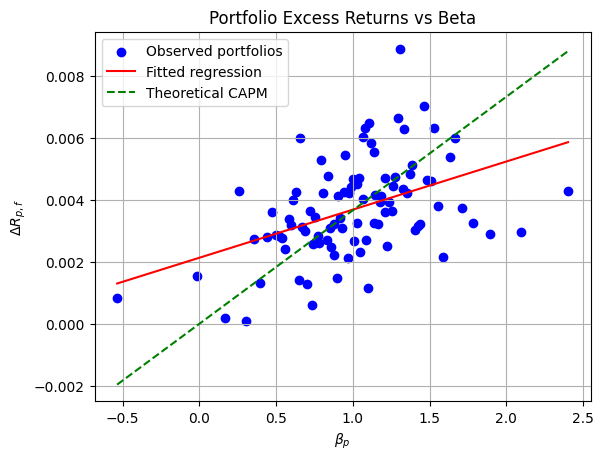

In [76]:
#2(d) v. Scatter Plot, Fitted Regression Line, Theoretical CAPM Line
plt.scatter(portfolio_avg['Beta'], portfolio_avg['AvgExcessReturn'], color='blue', label='Observed portfolios')

#fitted regression line
beta_range = np.linspace(portfolio_avg['Beta'].min(), portfolio_avg['Beta'].max(), 100)
fitted_line = cs_model.params['const'] + cs_model.params['Beta'] * beta_range
plt.plot(beta_range, fitted_line, color='red', linestyle='-', label='Fitted regression')

#theoretical CAPM line
theoretical_line = 0 + mean_market_excess_return * beta_range
plt.plot(beta_range, theoretical_line, color='green', linestyle='--', label='Theoretical CAPM')

plt.xlabel(r'$\beta_p$')
plt.ylabel(r'$\Delta R_{p,f}$')
plt.title('Portfolio Excess Returns vs Beta')
plt.legend()
plt.grid(True)
plt.show()